In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, mannwhitneyu

PROJECT_DIR = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

RAW_FILE = (
    PROJECT_DIR
    / "data"
    / "raw"
    / "default of credit card clients.xls"
)

REPORTS_DIR = PROJECT_DIR / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_excel(RAW_FILE, header=1)

df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

target = "default_payment_next_month"

print("Shape:", df.shape)
print("Default rate:", round(df[target].mean() * 100, 2), "%")

Shape: (30000, 25)
Default rate: 22.12 %


In [2]:
repayment_default = (
    df.groupby("pay_0")[target]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "customer_count",
        "mean": "default_rate"
    })
)

repayment_default["default_rate_pct"] = (
    repayment_default["default_rate"] * 100
)

display(repayment_default.round(3))

,customer_count,default_rate,default_rate_pct
pay_0,,,
-2,2759,0.132,13.229
-1,5686,0.168,16.778
0,14737,0.128,12.811
1,3688,0.339,33.948
2,2667,0.691,69.141
3,322,0.758,75.776
4,76,0.684,68.421
5,26,0.500,50.000
6,11,0.545,54.545


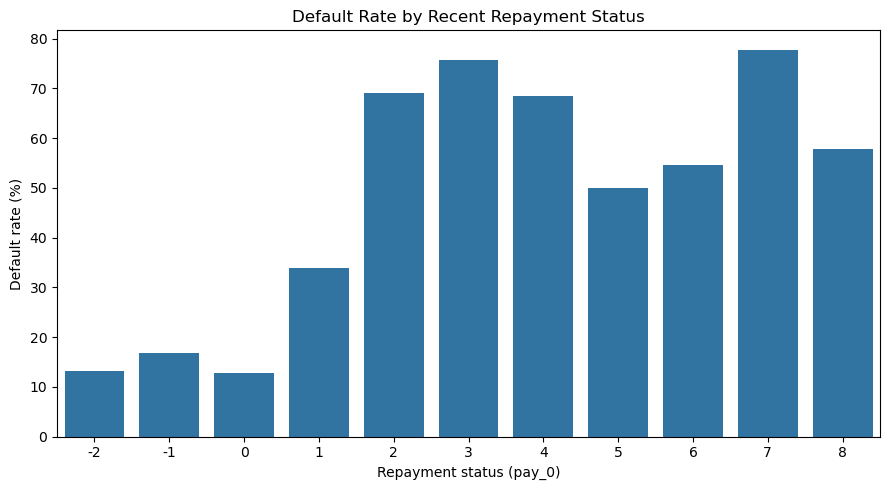

In [3]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=repayment_default.reset_index(),
    x="pay_0",
    y="default_rate_pct"
)

plt.title("Default Rate by Recent Repayment Status")
plt.xlabel("Repayment status (pay_0)")
plt.ylabel("Default rate (%)")
plt.tight_layout()
plt.show()

In [ ]:
contingency_table = pd.crosstab(
    df["pay_0"],
    df[target]
)

chi2, chi2_p_value, dof, expected = chi2_contingency(
    contingency_table
)

print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {chi2_p_value:.6g}")

if chi2_p_value < 0.05:
    print("Result: Evidence of an association at the 5% significance level.")
else:
    print("Result: Insufficient evidence of an association at the 5% significance level.")

In [ ]:
non_default = df.loc[df[target] == 0, "limit_bal"].dropna()
default = df.loc[df[target] == 1, "limit_bal"].dropna()

u_stat, mannwhitney_p_value = mannwhitneyu(
    non_default,
    default,
    alternative="two-sided"
)

print("Median credit limit — non-default:", non_default.median())
print("Median credit limit — default:", default.median())
print(f"Mann–Whitney U statistic: {u_stat:.3f}")
print(f"P-value: {mannwhitney_p_value:.6g}")

In [6]:
numeric_cols = [
    "limit_bal",
    "age",
    "bill_amt1",
    "bill_amt2",
    "bill_amt3",
    "pay_amt1",
    "pay_amt2",
    "pay_amt3",
    "pay_0",
    "pay_2",
    "pay_3",
    "pay_4",
    "pay_5",
    "pay_6"
]

correlations = (
    df[numeric_cols + [target]]
    .corr(numeric_only=True)[target]
    .drop(target)
    .sort_values()
)

display(
    correlations.to_frame("correlation_with_default")
    .round(4)
)

,correlation_with_default
limit_bal,-0.1535
pay_amt1,-0.0729
pay_amt2,-0.0586
pay_amt3,-0.0563
bill_amt1,-0.0196
bill_amt2,-0.0142
bill_amt3,-0.0141
age,0.0139
pay_6,0.1869
pay_5,0.2041


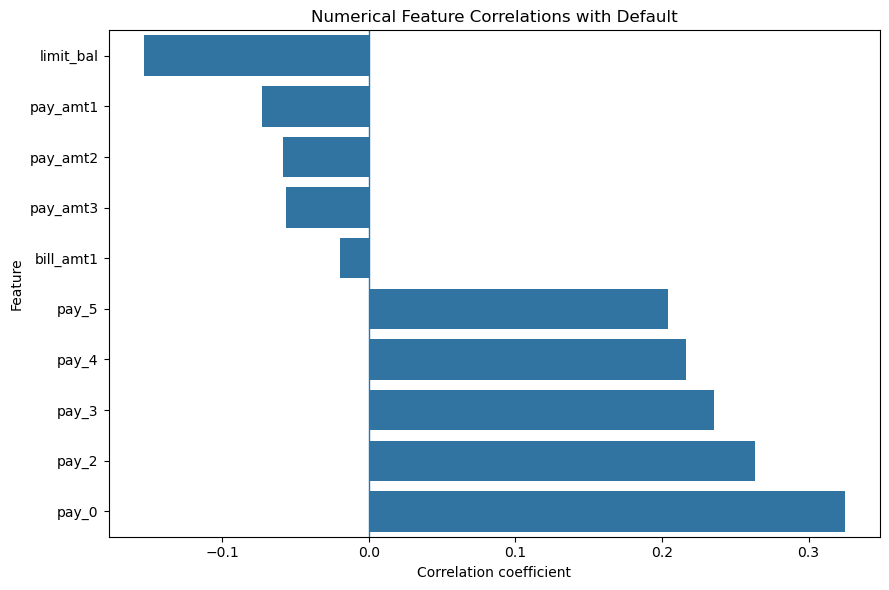

In [7]:
top_correlations = pd.concat([
    correlations.head(5),
    correlations.tail(5)
]).sort_values()

plt.figure(figsize=(9, 6))

sns.barplot(
    x=top_correlations.values,
    y=top_correlations.index
)

plt.axvline(0, linewidth=1)
plt.title("Numerical Feature Correlations with Default")
plt.xlabel("Correlation coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [ ]:
# Results are collected after both tests have run.


In [ ]:
statistical_results = pd.DataFrame([
    {"test": "Chi-square: pay_0 vs default", "statistic": chi2, "p_value": chi2_p_value},
    {"test": "Mann-Whitney U: credit limit by default", "statistic": u_stat, "p_value": mannwhitney_p_value}
])

display(statistical_results)
statistical_results.to_csv(REPORTS_DIR / "statistical_tests.csv", index=False)
correlations.rename("correlation_with_default").to_csv(REPORTS_DIR / "feature_correlations.csv")
print("Statistical results saved.")
